# Module 4 — Modèles de langue et réseaux récurrents

> **Objectif** : comprendre ce qu'est un **modèle de langue** (la tâche qui est au cœur de GPT), comment on le mesure (**perplexité**), pourquoi les n-grammes atteignent vite leurs limites, et comment les **réseaux récurrents** (RNN, LSTM, GRU) traitent des séquences de longueur arbitraire. On code un RNN caractère par caractère **de zéro en NumPy**, rétropropagation dans le temps comprise, et on analyse mathématiquement le problème du **gradient évanescent** qui a motivé les LSTM… puis les Transformers.

| | |
|---|---|
| **Durée estimée** | 3 h |
| **Prérequis** | Modules 0 à 3 |
| **Librairies** | `numpy`, `matplotlib` ; `torch` pour les sections 7–8 |

**Plan**

1. Qu'est-ce qu'un modèle de langue ?
2. Modèles n-grammes et perplexité
3. Le réseau récurrent (RNN)
4. Rétropropagation dans le temps (BPTT) : un char-RNN de zéro
5. Le gradient évanescent / explosif : l'analyse
6. LSTM et GRU : des autoroutes pour le gradient
7. Les RNN dans PyTorch : API, formes, *packing*
8. Un modèle de langue LSTM et la génération de texte
9. Au-delà : RNN bidirectionnels, étiquetage de séquences, limites
10. Récapitulatif et exercices

In [1]:
import re
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

# Corpus: Python's own documentation (ships with every Python install), lower-cased, restricted alphabet
from pydoc_data.topics import topics
ALPHABET = "abcdefghijklmnopqrstuvwxyz0123456789 .,:;()'\"-_=*[]<>+/"
raw = re.sub(r"\s+", " ", " ".join(topics.values()).lower())
text = "".join(c for c in raw if c in ALPHABET)
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = np.array([stoi[c] for c in text])
split = int(0.9 * len(data))
train_data, test_data = data[:split], data[split:]
print(f"{len(text):,} characters | vocabulary V = {V}")
print(repr(text[1000:1300]))

512,114 characters | vocabulary V = 55
' to "__debug__" are illegal. the value for the built-in variable is determined when the interpreter starts. assignment statements ********************* assignment statements are used to (re)bind names to values and to modify attributes or items of mutable objects: assignment_stmt ::= (target_list "='


## 1. Qu'est-ce qu'un modèle de langue ?

### 💡 Intuition

Un modèle de langue répond à la question : « **quelle est la probabilité de ce texte ?** », ou de façon équivalente : « **quel est le prochain mot (token) ?** ». Ton clavier de téléphone en est un. GPT en est un, très grand.

### 📐 Maths

Par la **règle de la chaîne** des probabilités, sans aucune approximation :
$$
p(w_1, w_2, \dots, w_T) = \prod_{t=1}^{T} p(w_t \mid w_1, \dots, w_{t-1}) = \prod_{t=1}^{T} p(w_t\mid w_{<t})
$$

Modéliser la langue revient donc à modéliser la **distribution du token suivant sachant le passé**. Toute la difficulté est que le passé $w_{<t}$ peut être arbitrairement long. Les familles de modèles diffèrent par la façon de **résumer** ce passé :

| Modèle | Résumé du passé |
|---|---|
| n-gramme | les $n-1$ derniers tokens, rien d'autre |
| RNN / LSTM | un vecteur d'état $h_t$ de taille fixe, mis à jour à chaque pas |
| Transformer | accès direct à tous les tokens passés, via l'attention (modules 5–6) |

**Entraînement** : on minimise l'entropie croisée du token suivant, $-\frac1T\sum_t \log p_\theta(w_t\mid w_{<t})$. Les étiquettes sont le texte lui-même décalé d'un cran : c'est de l'**apprentissage auto-supervisé**, comme word2vec.

**Génération** : on tire $w_1\sim p(\cdot)$, puis $w_2\sim p(\cdot\mid w_1)$, etc. (génération **autorégressive**).

## 2. Modèles n-grammes et perplexité

### 📐 L'hypothèse de Markov

On approxime $p(w_t\mid w_{<t}) \approx p(w_t\mid w_{t-n+1},\dots,w_{t-1})$ : seuls les $n-1$ derniers tokens comptent. L'estimation par maximum de vraisemblance est un simple **comptage** :
$$
\hat p(w_t\mid \text{ctx}) = \frac{\text{count}(\text{ctx}, w_t)}{\text{count}(\text{ctx})}
$$

**Problème** : un n-gramme jamais vu reçoit une probabilité nulle, et une seule probabilité nulle rend la probabilité de tout le texte nulle (perte infinie). Solution la plus simple : le **lissage additif** (add-$k$) :
$$
\hat p_k(w\mid\text{ctx}) = \frac{\text{count}(\text{ctx}, w) + k}{\text{count}(\text{ctx}) + kV}
$$
(Des lissages bien meilleurs existent, comme Kneser-Ney, mais l'idée est la même : retirer un peu de masse aux événements vus pour la donner aux non vus.)

### 📐 La perplexité

$$
\text{PPL} = \exp\left(-\frac{1}{T}\sum_{t=1}^{T}\log p(w_t\mid w_{<t})\right) = \exp(\text{entropie croisée moyenne})
$$

**Interprétation** : la perplexité est le **nombre effectif de choix équiprobables** que le modèle hésite à faire à chaque pas. Un modèle uniforme sur $V$ symboles a une perplexité de $V$ ; un modèle parfait, de 1. Plus bas = mieux. On exprime aussi souvent la perte en **bits par caractère** : $\text{bpc} = \text{CE}/\ln 2$.

> ⚠️ Les perplexités ne sont comparables qu'**à tokenisation égale** : une perplexité par caractère et une perplexité par sous-mot BPE ne se comparent pas directement.

In [2]:
def ngram_counts(seq, n):
    ctx_counts, full_counts = Counter(), Counter()
    s = "".join(chars[i] for i in seq)
    for i in range(n - 1, len(s)):
        ctx, w = s[i - n + 1:i], s[i]
        ctx_counts[ctx] += 1
        full_counts[(ctx, w)] += 1
    return ctx_counts, full_counts


def ngram_perplexity(seq, ctx_counts, full_counts, n, k=0.01):
    s = "".join(chars[i] for i in seq)
    nll = 0.0
    for i in range(n - 1, len(s)):
        ctx, w = s[i - n + 1:i], s[i]
        p = (full_counts.get((ctx, w), 0) + k) / (ctx_counts.get(ctx, 0) + k * V)
        nll -= np.log(p)
    return np.exp(nll / (len(s) - n + 1))


rows = []
for n in range(1, 9):
    cc, fc = ngram_counts(train_data, n)
    ppl_tr = ngram_perplexity(train_data[:100_000], cc, fc, n)
    ppl_te = ngram_perplexity(test_data, cc, fc, n)
    rows.append((n, ppl_tr, ppl_te, len(cc)))
    print(f"n={n}: {len(cc):7,} distinct contexts | train PPL {ppl_tr:6.2f} | test PPL {ppl_te:6.2f}")
rows = np.array(rows)

n=1:       1 distinct contexts | train PPL  23.04 | test PPL  25.81
n=2:      55 distinct contexts | train PPL  11.63 | test PPL  10.68
n=3:   1,672 distinct contexts | train PPL   5.73 | test PPL   6.45
n=4:   9,670 distinct contexts | train PPL   3.26 | test PPL   4.64
n=5:  27,625 distinct contexts | train PPL   2.41 | test PPL   4.61
n=6:  54,872 distinct contexts | train PPL   2.05 | test PPL   5.26
n=7:  86,080 distinct contexts | train PPL   1.85 | test PPL   6.35
n=8: 118,066 distinct contexts | train PPL   1.71 | test PPL   7.83


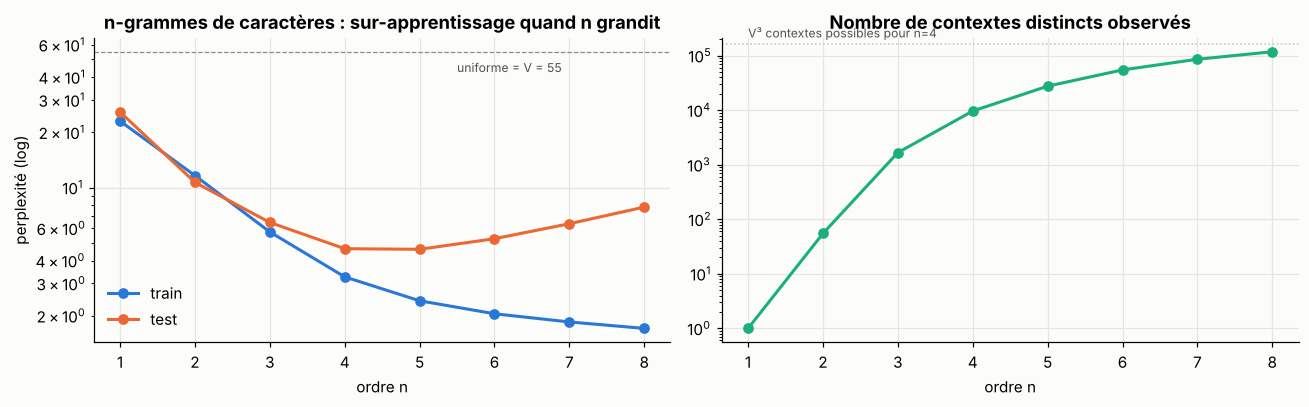

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(rows[:, 0], rows[:, 1], "o-", label="train")
axes[0].plot(rows[:, 0], rows[:, 2], "o-", label="test")
axes[0].axhline(V, color="#8a8984", ls="--", lw=0.8); axes[0].text(5.5, V * 0.9, f"uniforme = V = {V}", fontsize=8, color="#52514e", va="top")
axes[0].set_yscale("log"); axes[0].set_xlabel("ordre n"); axes[0].set_ylabel("perplexité (log)"); axes[0].legend()
axes[0].set_title("n-grammes de caractères : sur-apprentissage quand n grandit")
axes[1].semilogy(rows[:, 0], rows[:, 3], "o-", color=PALETTE[2])
axes[1].axhline(V ** 3, color="#c3c2b7", ls=":", lw=1); axes[1].text(1, V ** 3 * 1.3, "V³ contextes possibles pour n=4", fontsize=8, color="#52514e")
axes[1].set_xlabel("ordre n"); axes[1].set_title("Nombre de contextes distincts observés")
plt.tight_layout(); plt.show()

**Ce que montre la figure** : la perplexité de test baisse jusqu'à un certain $n$ puis **remonte**, tandis que celle d'entraînement continue de chuter. C'est le sur-apprentissage du module 0, sous sa forme la plus pure : le nombre de contextes possibles croît en $V^{n-1}$ (**malédiction de la dimension**), la plupart ne sont vus qu'une fois, et le modèle ne sait rien en dire. Surtout, un n-gramme ne **partage rien** entre contextes similaires : « the function returns » et « the method returns » sont deux contextes sans aucun lien.

**La réponse neuronale** (Bengio et al., 2003) : représenter le contexte par des **embeddings** (module 3) passés dans un réseau. Des contextes similaires ont des représentations similaires, donc des prédictions similaires. Et avec un RNN, le contexte n'a même plus de longueur fixe.

In [4]:
def sample_ngram(cc, fc, n, seed_text, length=200, temperature=1.0, r=None):
    r = r or np.random.default_rng(0)
    out = seed_text
    by_ctx = defaultdict(list)
    for (ctx, w), c in fc.items():
        by_ctx[ctx].append((w, c))
    for _ in range(length):
        cands = by_ctx.get(out[-(n - 1):] if n > 1 else "", [])
        if not cands:
            out += " "; continue
        ws, cs = zip(*cands)
        p = np.array(cs, dtype=float) ** (1 / temperature); p /= p.sum()
        out += ws[r.choice(len(ws), p=p)]
    return out

for n in [2, 4, 7]:
    cc, fc = ngram_counts(train_data, n)
    print(f"--- {n}-gram ---\n{sample_ngram(cc, fc, n, 'the '[:max(n - 1, 1)] if n > 1 else '', 160)}\n")

--- 2-gram ---
to "an, r  onasinamenthallsn.5* th iordun" ptee e of lerence thestonuntslickes*yit ite".foulfob(y 1.. anmes  ". ". biprss typltther d. clyp t ppracof on s crntth

--- 4-gram ---
the expr "co_celectly at also *othe resuminal that classed with the asyntaints escriptors beticale. orightml from lock. addediate respam, spend it would yields. wh

--- 7-gram ---
the    current bases, **kwds)" (the case any valid identifier that fails and global_stmt  try3_stmt try1_stmt ::= "**" expression1, expr, literals fallback in order



## 3. Le réseau récurrent (RNN)

### 💡 Intuition

Tu lis cette phrase mot par mot, en gardant en tête un **résumé** de ce que tu as lu jusqu'ici, que tu mets à jour à chaque mot. Un RNN fait exactement cela : il maintient un **état caché** $h_t$ (sa « mémoire de travail ») et le met à jour avec la même fonction à chaque pas de temps.

### 📐 Maths (RNN d'Elman)

$$
\begin{aligned}
h_t &= \tanh\big(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h\big) && h_t\in\mathbb R^{H}\\
z_t &= W_{hy}\,h_t + b_y && \text{logits du token suivant}\\
p(w_{t+1}\mid w_{\le t}) &= \mathrm{softmax}(z_t)
\end{aligned}
$$

avec $x_t$ l'embedding (ou le one-hot) du token $t$ et $h_0 = 0$.

Points clés :
- **Partage des paramètres** : les mêmes $W_{xh}, W_{hh}, W_{hy}$ servent à chaque pas de temps. Le nombre de paramètres ne dépend pas de la longueur de la séquence, et le modèle généralise à des longueurs jamais vues.
- **Mémoire théoriquement illimitée** : $h_t$ dépend de tout le passé.
- **Calcul séquentiel** : $h_t$ a besoin de $h_{t-1}$, impossible de paralléliser sur la dimension temporelle. C'est la faiblesse qui a fait gagner les Transformers sur GPU.

« Déplié » dans le temps, un RNN est un réseau profond de profondeur $T$, dont toutes les couches partagent les poids :

```
  z1        z2        z3              zT
  ↑         ↑         ↑               ↑
h0 → [h1] → [h2] → [h3] → … → [hT]
      ↑         ↑         ↑               ↑
      x1        x2        x3              xT
```

## 4. Rétropropagation dans le temps (BPTT) : un char-RNN de zéro

### 📐 Les gradients

La perte totale est $L = \sum_t \ell_t$ avec $\ell_t = -\log p(w_{t+1}\mid w_{\le t})$. On rétropropage dans le graphe déplié. En notant $\delta^z_t = \hat p_t - y_t$ (softmax + CE, module 0) et $a_t$ la pré-activation ($h_t = \tanh(a_t)$) :

$$
\begin{aligned}
\frac{\partial L}{\partial h_t} &= W_{hy}^\top\,\delta^z_t \;+\; \underbrace{W_{hh}^\top\,\delta^a_{t+1}}_{\text{gradient venant du futur}}\\
\delta^a_t = \frac{\partial L}{\partial a_t} &= \frac{\partial L}{\partial h_t}\odot(1-h_t^2)\\
\frac{\partial L}{\partial W_{hh}} &= \sum_t \delta^a_t\,h_{t-1}^\top,\qquad \frac{\partial L}{\partial W_{xh}} = \sum_t \delta^a_t\,x_t^\top,\qquad \frac{\partial L}{\partial W_{hy}} = \sum_t \delta^z_t\,h_t^\top
\end{aligned}
$$

Les gradients des paramètres partagés sont des **sommes sur le temps** (règle de la chaîne multivariée : un paramètre utilisé $T$ fois reçoit $T$ contributions).

**BPTT tronquée** : on découpe le texte en morceaux de $T$ tokens (ici 32). On **transmet l'état** $h$ d'un morceau au suivant (la mémoire continue), mais on **ne rétropropage pas** au-delà du morceau courant (en PyTorch : `h = h.detach()`).

In [5]:
class CharRNN:
    """Vanilla RNN language model in pure NumPy (one-hot inputs, tanh, softmax output)."""

    def __init__(self, V, H=128, seed=0):
        r = np.random.default_rng(seed)
        self.Wxh = r.normal(0, 0.01, (H, V))
        self.Whh = r.normal(0, 0.01, (H, H))
        self.Why = r.normal(0, 0.01, (V, H))
        self.bh, self.by = np.zeros(H), np.zeros(V)
        self.H, self.V = H, V

    def params(self):
        return [self.Wxh, self.Whh, self.Why, self.bh, self.by]

    def loss_and_grads(self, inputs, targets, h_prev):
        hs, ps = {-1: h_prev}, {}
        loss = 0.0
        for t, (i, j) in enumerate(zip(inputs, targets)):              # forward
            hs[t] = np.tanh(self.Wxh[:, i] + self.Whh @ hs[t - 1] + self.bh)   # Wxh @ one_hot(i) = column i
            z = self.Why @ hs[t] + self.by
            p = np.exp(z - z.max()); p /= p.sum()
            ps[t] = p
            loss -= np.log(p[j])
        dWxh, dWhh, dWhy = np.zeros_like(self.Wxh), np.zeros_like(self.Whh), np.zeros_like(self.Why)
        dbh, dby = np.zeros_like(self.bh), np.zeros_like(self.by)
        dh_next = np.zeros(self.H)                                     # gradient coming from the future
        for t in reversed(range(len(inputs))):                         # backward through time
            dz = ps[t].copy(); dz[targets[t]] -= 1                     # p - y
            dWhy += np.outer(dz, hs[t]); dby += dz
            dh = self.Why.T @ dz + dh_next
            da = (1 - hs[t] ** 2) * dh                                 # through tanh
            dbh += da
            dWxh[:, inputs[t]] += da
            dWhh += np.outer(da, hs[t - 1])
            dh_next = self.Whh.T @ da
        grads = [g / len(inputs) for g in (dWxh, dWhh, dWhy, dbh, dby)]   # we return the MEAN loss -> mean grads
        return loss / len(inputs), grads, hs[len(inputs) - 1]

    def sample(self, h, first_id, n, temperature=1.0, r=None):
        r = r or np.random.default_rng(0)
        x, out = first_id, [chars[first_id]]
        for _ in range(n):
            h = np.tanh(self.Wxh[:, x] + self.Whh @ h + self.bh)
            z = (self.Why @ h + self.by) / temperature
            p = np.exp(z - z.max()); p /= p.sum()
            x = r.choice(self.V, p=p)
            out.append(chars[x])
        return "".join(out)

**Toujours vérifier le gradient avant d'entraîner** (module 0) :

In [6]:
rnn_check = CharRNN(V, H=16, seed=1)
inp, tgt = train_data[:10], train_data[1:11]
_, grads, _ = rnn_check.loss_and_grads(inp, tgt, np.zeros(16))
names = ["Wxh", "Whh", "Why", "bh", "by"]
eps = 1e-5
for name, P, G in zip(names, rnn_check.params(), grads):
    num = np.zeros_like(P)
    flat_idx = rng.choice(P.size, size=min(20, P.size), replace=False)
    for fi in flat_idx:
        idx = np.unravel_index(fi, P.shape)
        old = P[idx]
        P[idx] = old + eps; lp, _, _ = rnn_check.loss_and_grads(inp, tgt, np.zeros(16))
        P[idx] = old - eps; lm, _, _ = rnn_check.loss_and_grads(inp, tgt, np.zeros(16))
        P[idx] = old
        num[idx] = (lp - lm) / (2 * eps)
    mask = np.zeros(P.size, bool); mask[flat_idx] = True; mask = mask.reshape(P.shape)
    rel = np.linalg.norm(G[mask] - num[mask]) / (np.linalg.norm(G[mask]) + np.linalg.norm(num[mask]) + 1e-12)
    print(f"{name:4s}: relative error {rel:.2e}", "✅" if rel < 1e-6 else "❌")

Wxh : relative error 9.23e-09 ✅
Whh : relative error 6.83e-07 ✅
Why : relative error 6.23e-08 ✅
bh  : relative error 4.03e-09 ✅
by  : relative error 3.45e-10 ✅


On entraîne avec **Adagrad** (chaque paramètre a un pas $\eta/\sqrt{\sum g^2}$, l'ancêtre de RMSProp) et un **écrêtage** des gradients à $\pm 5$ pour éviter les explosions (section 5).

In [7]:
def train_char_rnn(model, data, iters=20_000, T=32, lr=0.05, clip=5.0, log_every=2000, sample_at=(0, 2000, 8000, 20000)):
    mem = [np.zeros_like(p) for p in model.params()]
    h, pos = np.zeros(model.H), 0
    smooth, history, samples = np.log(V), [], {}
    for it in range(iters + 1):
        if it in sample_at:
            samples[it] = model.sample(np.zeros(model.H), stoi["t"], 150, temperature=0.8)
        if pos + T + 1 >= len(data):
            pos, h = 0, np.zeros(model.H)                    # restart from the beginning of the text
        inputs, targets = data[pos:pos + T], data[pos + 1:pos + T + 1]
        loss, grads, h = model.loss_and_grads(inputs, targets, h)   # h is carried over (truncated BPTT)
        for p_, g, m in zip(model.params(), grads, mem):
            np.clip(g, -clip, clip, out=g)                   # gradient clipping (element-wise)
            m += g * g
            p_ -= lr * g / np.sqrt(m + 1e-8)                 # Adagrad
        smooth = 0.99 * smooth + 0.01 * loss
        if it % 200 == 0:
            history.append((it, smooth))
        if it % log_every == 0:
            print(f"iter {it:6d} | smoothed loss {smooth:.3f} nats/char | PPL {np.exp(smooth):6.2f}")
        pos += T
    return np.array(history), samples


rnn = CharRNN(V, H=128)
hist_rnn, samples_rnn = train_char_rnn(rnn, train_data)

iter      0 | smoothed loss 4.007 nats/char | PPL  55.00
iter   2000 | smoothed loss 2.385 nats/char | PPL  10.86
iter   4000 | smoothed loss 2.114 nats/char | PPL   8.28
iter   6000 | smoothed loss 2.236 nats/char | PPL   9.35
iter   8000 | smoothed loss 1.919 nats/char | PPL   6.82
iter  10000 | smoothed loss 1.903 nats/char | PPL   6.71
iter  12000 | smoothed loss 2.158 nats/char | PPL   8.65
iter  14000 | smoothed loss 1.456 nats/char | PPL   4.29
iter  16000 | smoothed loss 1.766 nats/char | PPL   5.85
iter  18000 | smoothed loss 1.890 nats/char | PPL   6.62
iter  20000 | smoothed loss 1.793 nats/char | PPL   6.01


RNN (H=128) test perplexity: 7.15  |  best n-gram (n=5): 4.61
--- after 0 iterations ---
tg3' pvelawp s"l.sa5<"+hge:zyigi:,k_6[tw8c6d7:t1f)qo2t(7-=o1';/)c5h/w9*fv=x]<fzx>m]ao;lkw+lwy syx-ytq[1pv3a=w'le"k m_w(r(7<yb32t1+4dbpb4;pfx9bdr-;v'q;q

--- after 2000 iterations ---
the  ong96g: <+9/:706+/8776zq8786/9636__573756_07+:9/_+5/69/+6/+727/g5+7g6j667zg69669698g.8_g';qg/q;96/9g076g+97+9*96g+;+56i95/;/-176971697g577>/6g+;6:

--- after 8000 iterations ---
the  stornto taqnommaddexpryworsignommovenomentboctims mant, magndent. munvexpxvarngrgrex, ux*nzthons8._of kr.moct rit*_***x855g0********88x699n9mratex

--- after 20000 iterations ---
the  nvassto thing hace prowsinnd regurs oncempar statament and of is arround worn opermodegs tor usplested the "tares the useded defromestring ans ret



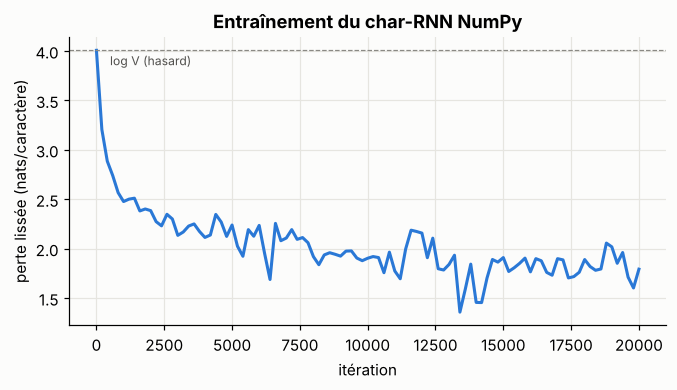

In [8]:
def eval_rnn(model, data, T=200):
    h, nll, n = np.zeros(model.H), 0.0, 0
    for pos in range(0, len(data) - T - 1, T):
        loss, _, h = model.loss_and_grads(data[pos:pos + T], data[pos + 1:pos + T + 1], h)
        nll += loss * T; n += T
    return np.exp(nll / n)

ppl_rnn = eval_rnn(rnn, test_data[:20_000])
best_ngram = rows[np.argmin(rows[:, 2])]
print(f"RNN (H=128) test perplexity: {ppl_rnn:.2f}  |  best n-gram (n={int(best_ngram[0])}): {best_ngram[2]:.2f}")
plt.figure(figsize=(7, 3.4))
plt.plot(hist_rnn[:, 0], hist_rnn[:, 1])
plt.axhline(np.log(V), color="#8a8984", ls="--", lw=0.8); plt.text(500, np.log(V) - 0.15, "log V (hasard)", fontsize=8, color="#52514e")
plt.xlabel("itération"); plt.ylabel("perte lissée (nats/caractère)"); plt.title("Entraînement du char-RNN NumPy")
plt.show()
for it, s in samples_rnn.items():
    print(f"--- after {it} iterations ---\n{s}\n")

> 🧪 **Lecture critique** : en une minute de CPU, le RNN passe du bruit pur à des « mots » plausibles, des espaces bien placés, des guillemets… mais pas encore de phrases sensées. Et sa perplexité de test est **moins bonne** que celle du meilleur n-gramme. Ce n'est pas une faiblesse du principe mais un **sous-entraînement** : 20 000 pas × 32 caractères ≈ 1,4 passage sur le corpus, 128 neurones, un optimiseur rudimentaire. Même le taux d'apprentissage compte énormément : un petit balayage ($\eta\in\{0.02, 0.03, 0.05, 0.1\}$) donne des perplexités de test de 7.7, 7.3, 7.1 et 10.8 ; on a gardé 0.05. Le 5-gramme, lui, « mémorise » 27 000 contextes d'une documentation très répétitive, dont le jeu de test provient. Le LSTM PyTorch de la section 8 (plus large, ~50 passages équivalents, AdamW) devrait passer nettement sous la barre des n-grammes : vérifie-le quand tu l'exécutes. Leçon générale : **une comparaison de modèles n'a de sens qu'à budget de calcul et de réglage comparable**.

## 5. Le gradient évanescent (ou explosif) : l'analyse

### 📐 Maths

Combien l'état à l'instant $t$ influence-t-il la perte à l'instant $T\gg t$ ? Par la règle de la chaîne :
$$
\frac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T}\frac{\partial h_k}{\partial h_{k-1}} = \prod_{k=t+1}^{T}\mathrm{diag}\big(1-h_k^2\big)\,W_{hh}
$$

C'est un **produit de $T-t$ matrices**. En norme :
$$
\left\lVert\frac{\partial h_T}{\partial h_t}\right\rVert \le \prod_{k}\left\lVert\mathrm{diag}(1-h_k^2)\right\rVert\,\lVert W_{hh}\rVert \le \big(\gamma\,\sigma_{\max}(W_{hh})\big)^{T-t}
$$
avec $\gamma\le 1$ la borne de la dérivée de tanh et $\sigma_{\max}$ la plus grande valeur singulière. Un nombre $<1$ élevé à la puissance 50 tend vers 0 (**gradient évanescent**) ; un nombre $>1$, vers l'infini (**gradient explosif**).

Conséquence concrète : un RNN simple **n'apprend pratiquement pas de dépendances au-delà de 10 à 20 pas**. Dans « Les *clés* que j'ai laissées sur la table de la cuisine hier soir *sont*… », l'accord de « sont » dépend d'un mot 12 tokens plus tôt. Le signal d'erreur qui devrait corriger le traitement de « clés » arrive multiplié par un nombre minuscule.

- **Explosion** → on la contrôle par l'**écrêtage du gradient** (module 1).
- **Évanescence** → aucun remède simple sur un RNN : il faut changer d'architecture (LSTM, puis attention).

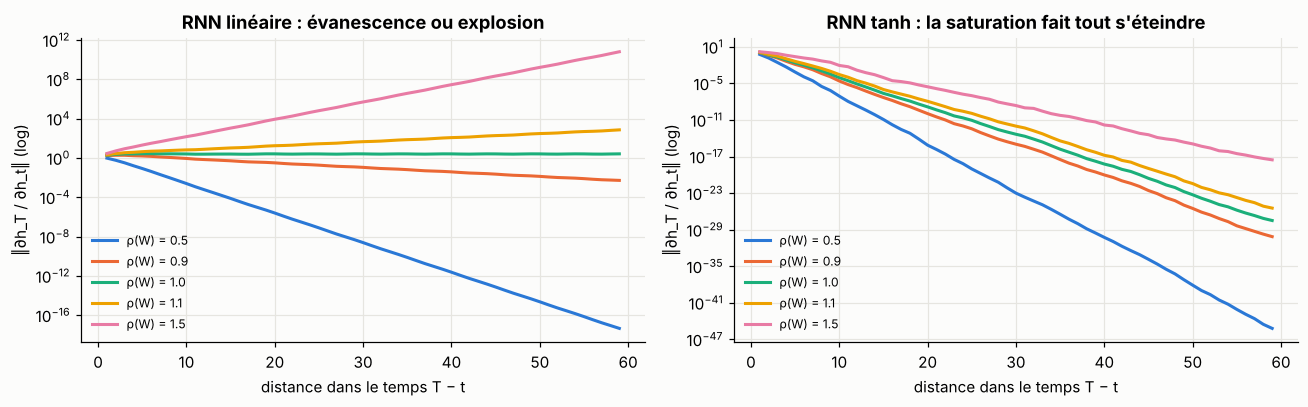

In [9]:
def jacobian_norms(rho, T=60, H=64, seed=0, activation="tanh"):
    """|| d h_T / d h_{T-k} || for k = 1..T along a random trajectory, with W_hh of spectral radius rho."""
    r = np.random.default_rng(seed)
    W = r.normal(0, 1, (H, H))
    W *= rho / np.max(np.abs(np.linalg.eigvals(W)))
    Wx = r.normal(0, 1, (H, H)) * 0.5
    hs, h = [], np.zeros(H)
    for _ in range(T):
        h = np.tanh(W @ h + Wx @ r.normal(0, 1, H)) if activation == "tanh" else W @ h + Wx @ r.normal(0, 1, H)
        hs.append(h)
    J, norms = np.eye(H), []
    for k in range(T - 1, 0, -1):                       # multiply Jacobians backwards from T
        D = np.diag(1 - hs[k] ** 2) if activation == "tanh" else np.eye(H)
        J = J @ D @ W
        norms.append(np.linalg.norm(J, 2))
    return np.array(norms)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for rho, c in zip([0.5, 0.9, 1.0, 1.1, 1.5], PALETTE):
    axes[0].semilogy(range(1, 60), jacobian_norms(rho, activation="linear"), color=c, label=f"ρ(W) = {rho}")
    axes[1].semilogy(range(1, 60), jacobian_norms(rho), color=c, label=f"ρ(W) = {rho}")
axes[0].set_title("RNN linéaire : évanescence ou explosion"); axes[1].set_title("RNN tanh : la saturation fait tout s'éteindre")
for ax in axes:
    ax.set_xlabel("distance dans le temps T − t"); ax.set_ylabel("‖∂h_T / ∂h_t‖ (log)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**À gauche**, sans non-linéarité, tout dépend du rayon spectral $\rho(W)$ : décroissance exponentielle si $\rho<1$, explosion si $\rho>1$, et un « fil du rasoir » à $\rho = 1$. **À droite**, avec tanh et des entrées assez fortes pour saturer une partie des neurones (situation courante) : même avec $\rho>1$, $1-h^2\approx 0$ sur les neurones saturés et le gradient s'éteint quand même. Régler $W$ ne suffit pas : on oscille entre explosion et extinction, et la zone intermédiaire est étroite et instable. Le problème est **structurel** : un produit de nombreuses matrices.

## 6. LSTM et GRU : des autoroutes pour le gradient

### 💡 Intuition

Le défaut du RNN : à chaque pas, la mémoire est **entièrement réécrite** par une multiplication matricielle suivie d'un tanh. Le LSTM (Hochreiter & Schmidhuber, 1997) ajoute une **cellule mémoire** $c_t$ mise à jour de façon **additive**, contrôlée par des **portes** (des sigmoïdes entre 0 et 1, comme des robinets) :

- **porte d'oubli** $f_t$ : quelle part de l'ancienne mémoire garder ;
- **porte d'entrée** $i_t$ : quelle part de la nouvelle information écrire ;
- **porte de sortie** $o_t$ : quelle part de la mémoire exposer dans $h_t$.

### 📐 Maths

Avec $[h_{t-1}, x_t]$ la concaténation :
$$
\begin{aligned}
f_t &= \sigma(W_f[h_{t-1},x_t]+b_f) & i_t &= \sigma(W_i[h_{t-1},x_t]+b_i)\\
o_t &= \sigma(W_o[h_{t-1},x_t]+b_o) & \tilde c_t &= \tanh(W_c[h_{t-1},x_t]+b_c)\\
c_t &= f_t\odot c_{t-1} + i_t\odot\tilde c_t & h_t &= o_t\odot\tanh(c_t)
\end{aligned}
$$

**Pourquoi ça résout (en grande partie) le problème** : le long du chemin de la cellule,
$$
\frac{\partial c_t}{\partial c_{t-1}} = \mathrm{diag}(f_t) \quad(+\text{ termes indirects via } h_{t-1})
$$
Pas de multiplication par $W$, pas de dérivée de tanh : si la porte d'oubli vaut ≈ 1, le gradient traverse des dizaines de pas **presque intact**. C'est la même idée que les **connexions résiduelles** des Transformers ($x + f(x)$) : un chemin additif où le gradient circule librement. D'où l'astuce classique : **initialiser le biais de la porte d'oubli à 1** (ou plus), pour que le réseau « se souvienne par défaut » au début de l'entraînement.

**GRU** (Cho et al., 2014) : une version simplifiée à deux portes, sans cellule séparée, souvent aussi performante avec moins de paramètres :
$$
\begin{aligned}
z_t &= \sigma(W_z[h_{t-1},x_t]) && \text{(mise à jour)}\\
r_t &= \sigma(W_r[h_{t-1},x_t]) && \text{(réinitialisation)}\\
\tilde h_t &= \tanh(W[r_t\odot h_{t-1}, x_t]) \\
h_t &= (1-z_t)\odot h_{t-1} + z_t\odot\tilde h_t && \text{(interpolation : encore un chemin additif)}
\end{aligned}
$$

**Nombre de paramètres** pour une entrée de taille $D$ et un état de taille $H$ : RNN $H(H+D)+H$ ; GRU $3\times$ ; LSTM $4\times$ cela.

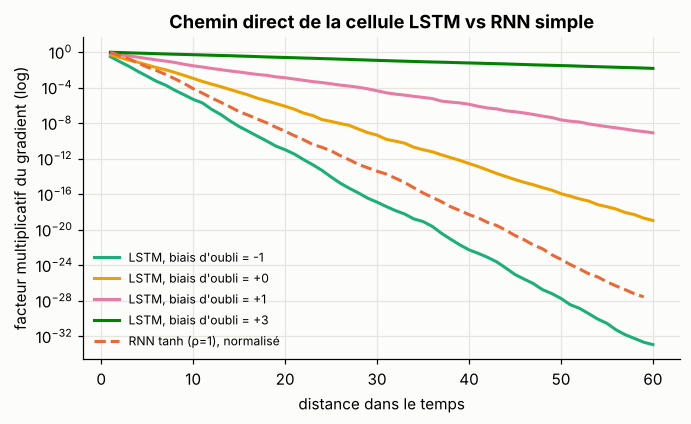

In [10]:
# Direct-path gradient through the LSTM cell: prod_k f_k, for different forget-gate biases
T_ = 60
fig, ax = plt.subplots(figsize=(7, 3.8))
for b_f, c in zip([-1.0, 0.0, 1.0, 3.0], PALETTE[2:]):
    f = 1 / (1 + np.exp(-(b_f + rng.normal(0, 1, (T_, 64)))))     # forget gates with some input-driven noise
    path = np.cumprod(f, axis=0).mean(1)                            # average over cell units
    ax.semilogy(range(1, T_ + 1), path, color=c, label=f"LSTM, biais d'oubli = {b_f:+.0f}")
ax.semilogy(range(1, 60), jacobian_norms(1.0) / jacobian_norms(1.0)[0], color=PALETTE[1], ls="--", label="RNN tanh (ρ=1), normalisé")
ax.set_xlabel("distance dans le temps"); ax.set_ylabel("facteur multiplicatif du gradient (log)")
ax.set_title("Chemin direct de la cellule LSTM vs RNN simple"); ax.legend(fontsize=8)
plt.show()

> ⚠️ **Nuance** : le LSTM *atténue* le problème, il ne l'élimine pas. Un LSTM gère bien des dépendances de quelques dizaines à une centaine de tokens, au-delà la mémoire de taille fixe $c_t\in\mathbb R^H$ devient un **goulot d'étranglement** : tout le passé doit tenir dans un vecteur. L'attention (module 5) supprime ce goulot en permettant de consulter directement n'importe quel état passé.

## 7. Les RNN dans PyTorch : API, formes, *packing*

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
B, T, D, H = 4, 7, 16, 32
x = torch.randn(B, T, D)
lstm = nn.LSTM(input_size=D, hidden_size=H, num_layers=2, batch_first=True, dropout=0.1, bidirectional=False)
out, (h_n, c_n) = lstm(x)            # initial states default to zeros
print("out:", out.shape)             # (B, T, H): top-layer hidden state at EVERY time step
print("h_n:", h_n.shape)             # (num_layers * num_directions, B, H): LAST time step, every layer
print("c_n:", c_n.shape)
print("out[:, -1] == h_n[-1]:", torch.allclose(out[:, -1], h_n[-1]))
print("parameters:", sum(p.numel() for p in lstm.parameters()))   # 4*(H*(D+H) + 2H) for layer 1 (PyTorch has 2 bias vectors)

**Les deux sorties, deux usages** :
- `out` (tous les pas de temps) → **modèle de langue** (prédire à chaque position) et **étiquetage de séquence** (une étiquette par token) ;
- `h_n` (dernier pas) → **classification de séquence** (une étiquette par phrase).

**Le piège du padding** : avec des séquences de longueurs différentes paddées à droite, `h_n` correspond au dernier pas **paddé**, pas au dernier vrai token ! Deux solutions : récupérer `out` à la position `longueur − 1` de chaque séquence, ou utiliser `pack_padded_sequence`, qui fait sauter les PAD au RNN.

In [ ]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

lengths = torch.tensor([7, 3, 5, 2])
x_padded = torch.randn(B, T, D)
for i, L in enumerate(lengths):
    x_padded[i, L:] = 0.0                                             # PAD positions

gru = nn.GRU(D, H, batch_first=True)
packed = pack_padded_sequence(x_padded, lengths, batch_first=True, enforce_sorted=False)
packed_out, h_last = gru(packed)                                      # h_last = state at each TRUE last token
out_unpacked, out_lengths = pad_packed_sequence(packed_out, batch_first=True)

out_naive, h_naive = gru(x_padded)                                    # without packing: PADs are processed!
manual_last = out_naive[torch.arange(B), lengths - 1]                 # gather the true last step
print("packed h == state at true last token:", torch.allclose(h_last[0], manual_last, atol=1e-6))
print("naive h_n (after PADs) differs:", not torch.allclose(h_naive[0], manual_last))

## 8. Un modèle de langue LSTM et la génération de texte

Le même modèle de langue qu'en section 4, version PyTorch : embeddings au lieu de one-hot, LSTM à 2 couches, AdamW, **BPTT tronquée** avec `detach()`, et **weight tying** (la matrice de sortie partage ses poids avec la matrice d'embeddings, ce qui économise $V\times d$ paramètres et régularise ; utilisé dans GPT-2).

In [ ]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, V, d=256, n_layers=2, dropout=0.2, tie_weights=True):
        super().__init__()
        self.emb = nn.Embedding(V, d)
        self.lstm = nn.LSTM(d, d, n_layers, batch_first=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(d, V)
        if tie_weights:
            self.head.weight = self.emb.weight          # same Parameter object: shared
        for name, p in self.lstm.named_parameters():    # forget-gate bias = 1 (gates are ordered i, f, g, o)
            if "bias" in name:
                p.data.fill_(0.0)
                p.data[d:2 * d].fill_(0.5)              # two bias vectors (ih and hh) -> total 1.0

    def forward(self, idx, state=None):
        h, state = self.lstm(self.drop(self.emb(idx)), state)
        return self.head(self.drop(h)), state           # logits (B, T, V)


def get_batch(data_t, B, T, gen):
    starts = torch.randint(0, len(data_t) - T - 1, (B,), generator=gen)
    x = torch.stack([data_t[s:s + T] for s in starts])
    y = torch.stack([data_t[s + 1:s + T + 1] for s in starts])
    return x, y                                          # y = x shifted by one: next-token targets


device = "cuda" if torch.cuda.is_available() else "cpu"
train_t, test_t = torch.tensor(train_data), torch.tensor(test_data)
lm = LSTMLanguageModel(V).to(device)
opt = torch.optim.AdamW(lm.parameters(), lr=2e-3, weight_decay=0.01)
gen = torch.Generator().manual_seed(0)
steps = 3000                                             # ~ a few minutes on CPU, < 1 min on GPU
for step in range(steps + 1):
    lm.train()
    x, y = (t.to(device) for t in get_batch(train_t, 64, 128, gen))
    logits, _ = lm(x)
    loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))   # flatten (B,T,V) -> (B*T, V)
    opt.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(lm.parameters(), 1.0)
    opt.step()
    if step % 500 == 0:
        print(f"step {step:5d} | train loss {loss.item():.3f} | PPL {loss.exp().item():.2f}")


@torch.no_grad()
def evaluate_lm(model, data_t, T=256):
    model.eval()
    state, nll, n = None, 0.0, 0
    for s in range(0, len(data_t) - T - 1, T):           # stateful evaluation: carry the state across chunks
        x = data_t[s:s + T].unsqueeze(0).to(device)
        y = data_t[s + 1:s + T + 1].unsqueeze(0).to(device)
        logits, state = model(x, state)
        nll += F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), reduction="sum").item(); n += T
    return np.exp(nll / n)

print(f"LSTM test perplexity: {evaluate_lm(lm, test_t[:50_000]):.2f}   (numpy RNN: {ppl_rnn:.2f})")

### Stratégies d'échantillonnage

À chaque pas, le modèle donne une distribution $p$ sur le token suivant. Comment choisir ?

| Stratégie | Règle | Effet |
|---|---|---|
| **Greedy** | $\arg\max p$ | déterministe, répétitif, boucles |
| **Température** $T$ | $\mathrm{softmax}(z/T)$ | $T<1$ prudent, $T>1$ créatif/chaotique (module 0) |
| **Top-$k$** | ne garder que les $k$ tokens les plus probables, renormaliser | coupe la longue traîne absurde |
| **Top-$p$ (nucleus)** | garder le plus petit ensemble dont la masse cumulée $\ge p$ | taille adaptative selon la confiance |

In [ ]:
@torch.no_grad()
def generate(model, prompt, n=300, temperature=1.0, top_k=None, top_p=None, seed=0):
    model.eval()
    g = torch.Generator(device="cpu").manual_seed(seed)
    idx = torch.tensor([[stoi[c] for c in prompt]], device=device)
    logits, state = model(idx)                          # "prefill": read the whole prompt
    out = prompt
    for _ in range(n):
        z = logits[0, -1] / max(temperature, 1e-6)
        if top_k is not None:
            kth = torch.topk(z, top_k).values[-1]
            z = z.masked_fill(z < kth, float("-inf"))
        if top_p is not None:
            sorted_z, order = torch.sort(z, descending=True)
            cum = torch.softmax(sorted_z, -1).cumsum(-1)
            drop = cum - torch.softmax(sorted_z, -1) > top_p      # keep tokens until mass >= top_p
            z[order[drop]] = float("-inf")
        nxt = torch.multinomial(torch.softmax(z, -1).cpu(), 1, generator=g).item()
        out += chars[nxt]
        logits, state = model(torch.tensor([[nxt]], device=device), state)   # one step, reuse the state
    return out

for kw in [dict(temperature=0.01), dict(temperature=0.7), dict(temperature=1.3), dict(temperature=1.0, top_p=0.9)]:
    print(f"--- {kw} ---\n{generate(lm, 'the for statement ', 200, **kw)}\n")

On visualise l'effet de ces filtres sur une distribution réaliste (longue traîne) :

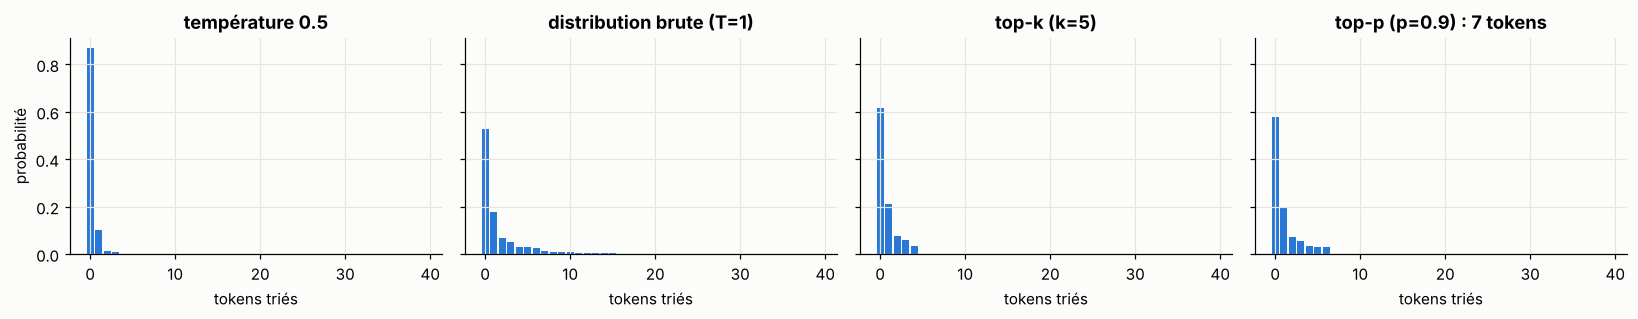

In [11]:
z = np.sort(rng.gumbel(size=40) * 1.6)[::-1]
def softmax(v): e = np.exp(v - v.max()); return e / e.sum()
p_full = softmax(z)
k = 5
p_topk = np.where(np.arange(40) < k, p_full, 0); p_topk /= p_topk.sum()
cum = np.cumsum(p_full); keep = (cum - p_full) < 0.9
p_topp = np.where(keep, p_full, 0); p_topp /= p_topp.sum()
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, (p_, title) in zip(axes, [(softmax(z / 0.5), "température 0.5"), (p_full, "distribution brute (T=1)"),
                                  (p_topk, f"top-k (k={k})"), (p_topp, f"top-p (p=0.9) : {keep.sum()} tokens")]):
    ax.bar(range(40), p_, color=PALETTE[0], width=0.8); ax.set_title(title); ax.set_xlabel("tokens triés")
axes[0].set_ylabel("probabilité")
plt.tight_layout(); plt.show()

## 9. Au-delà : RNN bidirectionnels, étiquetage de séquences, limites

**RNN bidirectionnel** : un RNN lit de gauche à droite, un second de droite à gauche, et on concatène leurs états : $h_t = [\overrightarrow{h_t};\overleftarrow{h_t}]$. Chaque position voit **tout** le contexte. Interdit pour un modèle de langue (on verrait le futur à prédire !), idéal pour **l'étiquetage de séquences** : reconnaissance d'entités nommées, étiquetage morpho-syntaxique, ou **délimitation de régions dans une séquence biologique** (une étiquette par acide aminé). Avant BERT, l'état de l'art de la NER était un **BiLSTM-CRF**. ELMo (2018) produisait des embeddings contextuels avec un BiLSTM pré-entraîné comme modèle de langue.

In [ ]:
class BiLSTMTagger(nn.Module):
    """One label per token (e.g. BIO tags for entities, or region labels for residues)."""

    def __init__(self, V, n_tags, d=128, H=128, pad_id=0):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=pad_id)
        self.lstm = nn.LSTM(d, H, batch_first=True, bidirectional=True, num_layers=2, dropout=0.1)
        self.head = nn.Linear(2 * H, n_tags)             # 2H: forward + backward states

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(self.emb(ids), lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=ids.shape[1])
        return self.head(out)                            # (B, T, n_tags)

tagger = BiLSTMTagger(V=100, n_tags=5)
ids = torch.randint(1, 100, (3, 12)); lengths = torch.tensor([12, 8, 5])
logits = tagger(ids, lengths)
tags = torch.randint(0, 5, (3, 12))
tags[torch.arange(12)[None, :] >= lengths[:, None]] = -100   # ignore PAD positions in the loss
loss = F.cross_entropy(logits.reshape(-1, 5), tags.reshape(-1), ignore_index=-100)
print(logits.shape, loss.item())

> 💡 `ignore_index=-100` est la convention PyTorch (et Hugging Face) pour exclure des positions de la perte : PAD, et aussi les sous-mots non initiaux en NER (module 7).

### Les limites qui ont mené aux Transformers

1. **Séquentialité** : $T$ pas de calcul dépendants les uns des autres, impossible à paralléliser sur GPU. Entraîner sur des milliards de tokens devient prohibitif.
2. **Goulot d'étranglement** : tout le passé doit tenir dans un vecteur de taille fixe.
3. **Dépendances longues** : même un LSTM peine au-delà de quelques centaines de tokens.

L'**attention** (module 5) attaque le point 2, le **Transformer** (module 6) supprime les trois.

> 📎 Les idées récurrentes reviennent pourtant aujourd'hui avec les **modèles à espace d'états** (S4, Mamba) et les RNN linéaires (RWKV), qui combinent un entraînement parallélisable et une inférence en mémoire constante.

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Modèle de langue | $p(w_{1:T}) = \prod_t p(w_t\mid w_{<t})$ ; entraîné par CE sur le token suivant |
| Perplexité | $\exp(\text{CE})$ ; nombre effectif de choix ; comparable à tokenisation égale |
| n-grammes | comptage + lissage ; explosion combinatoire en $V^{n-1}$, aucun partage |
| RNN | $h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)$ ; poids partagés dans le temps |
| BPTT | gradients sommés sur le temps ; tronquée : on transmet $h$ mais on `detach()` |
| Gradient évanescent | produit de jacobiennes $\approx(\gamma\sigma_{\max})^{T-t}$ |
| LSTM / GRU | portes + chemin additif ; biais d'oubli à 1 ; ~4×/3× les paramètres d'un RNN |
| PyTorch | `out` (tous les pas) vs `h_n` (dernier) ; `pack_padded_sequence` ; `ignore_index=-100` |
| Génération | greedy, température, top-k, top-p |

### 🏋️ Exercices

1. **Lissage.** Trace la perplexité de test du 5-gramme en fonction de $k\in\{10^{-4},\dots,1\}$. Pourquoi un $k$ trop grand est-il catastrophique quand $V$ est grand ?
2. **Mémoire du RNN.** Crée une tâche synthétique : une séquence aléatoire dont le **premier** symbole doit être prédit au **dernier** pas. Mesure la précision d'un RNN simple et d'un LSTM (PyTorch) en fonction de la longueur (5, 10, 20, 50, 100).
3. **Biais d'oubli.** Dans `LSTMLanguageModel`, compare un biais d'oubli de 0 et de 1 sur les 500 premiers pas d'entraînement.
4. **GRU de zéro.** Écris la passe avant d'une cellule GRU en NumPy et vérifie-la contre `nn.GRUCell` (attention à l'ordre des portes dans `weight_ih` : `r, z, n`, et au fait que PyTorch applique $r_t$ **après** la multiplication par $W_{hn}$).
5. **Beam search.** Implémente une recherche en faisceau (largeur 5) pour la génération. Pourquoi produit-elle un texte plus probable mais souvent plus fade que l'échantillonnage ?

<details><summary>Indications</summary>

1. Avec $k=1$ et un contexte vu peu de fois, le dénominateur est dominé par $kV$ : la distribution redevient quasi uniforme.
2. Le RNN simple tombe au hasard dès quelques dizaines de pas ; le LSTM tient beaucoup plus longtemps (mais pas indéfiniment).
4. PyTorch : $n_t = \tanh(W_{in}x_t + b_{in} + r_t\odot(W_{hn}h_{t-1}+b_{hn}))$, $h_t = (1-z_t)\odot n_t + z_t\odot h_{t-1}$ (le rôle de $z$ est inversé par rapport à la formule du cours).
5. Le beam search maximise la probabilité de la séquence ; or le texte humain n'est **pas** le texte le plus probable (Holtzman et al., 2020, « The Curious Case of Neural Text Degeneration »).
</details>

**➡️ Module suivant : seq2seq et attention** (encodeur-décodeur, teacher forcing, attention de Bahdanau et de Luong, visualisation des alignements).